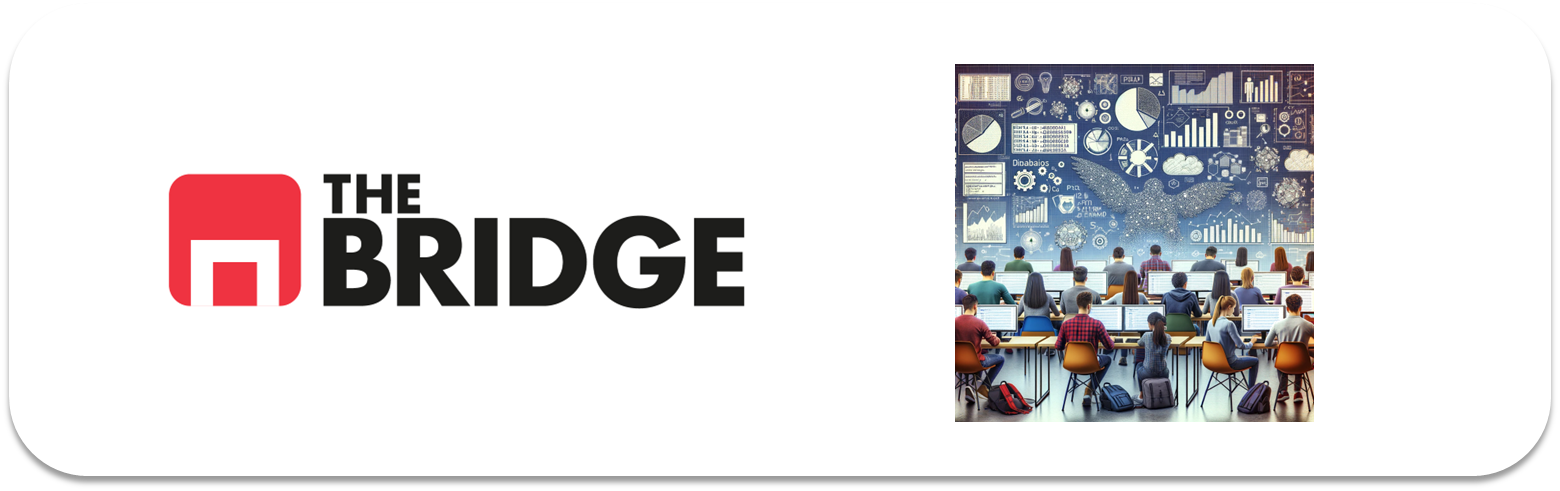

## PRÁCTICA: **Regresión Polinómica y Regularización**

* La práctica consiste en retomar el problema de la práctica de regresión lineal (predecir el valor de las viviendas de Boston) e intentar mejorar el modelo con regresión polinómica y regularización. Puedes aprovechar el trabajo de la práctica anterior, no hace falta repetir el proceso entero.

### Modelo de Regresión Polinómica y Regularización

El objetivo del modelo que tienes que construir es predecir la mediana del precio de las casas en una zona del área metropolitana de Boston dadas las características de las mismas. Es el mismo problema de la práctica de regresión lineal.

Aquí tienes una descripción de las variables del dataset, del que tendrás que decidir el target:  

***CRIM:*** Tasa de criminalidad per cápita por ciudad  
***ZN:*** Proporción de terreno residencial destinado a lotes de más de 25,000 pies cuadrados  
***INDUS:*** Proporción de acres de negocios no minoristas por ciudad  
***CHAS:*** Variable ficticia del río Charles (= 1 si el sector limita con el río; 0 en caso contrario)  
***NOX:*** Concentración de óxidos de nitrógeno (partes por 10 millones)  
***RM:*** Número promedio de habitaciones por vivienda  
***AGE:*** Proporción de unidades ocupadas por el propietario construidas antes de 1940  
***DIS:*** Distancias ponderadas a cinco centros de empleo de Boston  
***RAD:*** Índice de accesibilidad a autopistas radiales  
***TAX:*** Tasa de impuesto sobre la propiedad de valor total por $10,000  
***PTRATIO:*** Relación alumno-maestro por ciudad  
***LSTAT:*** % de población de estatus socioeconómico bajo  
***MEDV:*** Valor mediano de las viviendas ocupadas por sus propietarios en miles de dólares  

### Indicaciones

A continuación tienes las indicaciones para hacer el modelado. No necesariamente tienes que seguirlas al pie de la letra: son una guía con objetivos específicos, claros y determinados.

En concreto se pide partir de un modelo de regresión lineal (puedes reutilizar tu práctica de la unidad anterior), construir regresiones polinómicas de al menos dos grados distintos, evaluarlas contra un dataset de test reservado del original mostrando MAE, RMSE, MSE y $R^2$ y analizando si sobreajustan, y regularizar al menos uno de los modelos polinómicos probando como mínimo 3 valores diferentes de `alpha`.

Los pasos para guiar el trabajo:
1. Carga el dataset y repite (o reutiliza) la preparación de la práctica de regresión lineal: target, split train/test, mini-EDA, selección y tratamiento de las features.
2. Entrena una regresión lineal como baseline y evalúala en train y en test.
3. Genera features polinómicas (al menos de grado 2 y 3) a partir de las features numéricas. Recuerda ajustar (`fit`) `PolynomialFeatures` y el escalado solo con los datos de train. ¿Tiene sentido elevar al cuadrado las variables binarias o las dummies de las categóricas?
4. Entrena regresiones lineales con esas features y compara sus errores de train y test con los del baseline. ¿Mejoran? ¿Sobreajusta alguno de los grados?
5. Regulariza el modelo polinómico que más sobreajuste con Ridge, Lasso o ElasticNet, probando al menos 3 valores de `alpha`.
6. Compara gráficamente las predicciones de tu mejor modelo con los valores reales.
7. Expresa tus conclusiones: ¿con qué modelo te quedarías? ¿por qué?


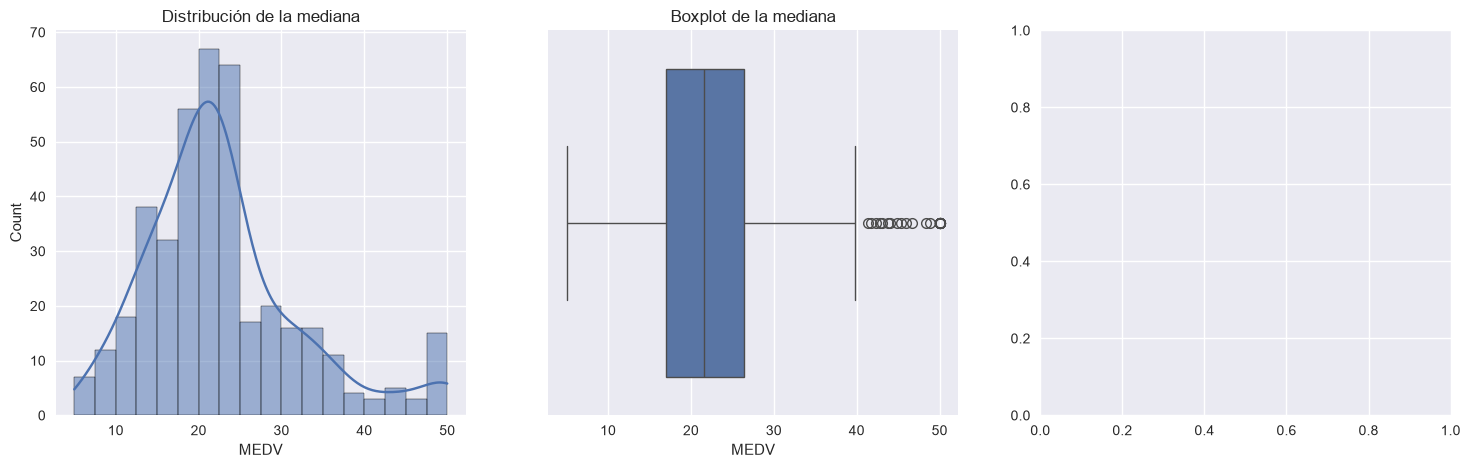

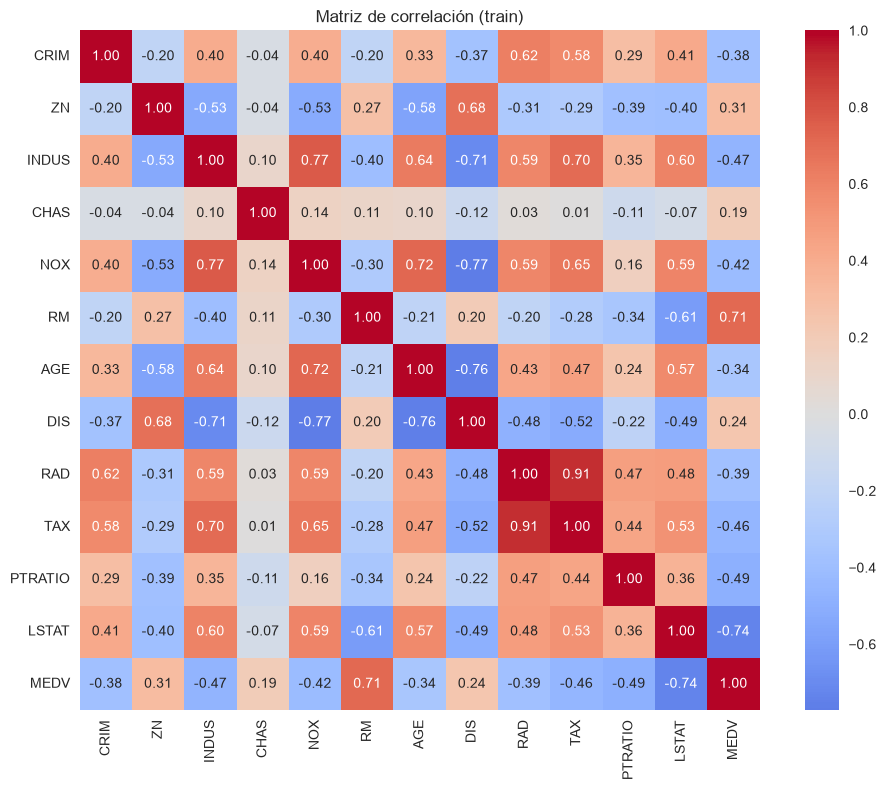

In [3]:
import pandas as pd 
import numpy as np 
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as snn
plt.style.use('seaborn-v0_8')
from scipy import stats

boston=pd.read_csv("../data/boston_fixed.csv", sep="|")
boston.head(10)

# DIVIDO 
# features
X=boston[["CRIM", "ZN", "INDUS", "CHAS", "NOX","RM","AGE","DIS", "RAD", "TAX", "PTRATIO", "LSTAT"]]
# target
y=boston["MEDV"]

X_train, X_test, y_train, y_test = train_test_split(X , y, test_size=0.2, random_state=42)

# 1. Histograma + KDE: forma de la distribución
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
snn.histplot(y_train, kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de la mediana")

# 2. Boxplot: outliers y dispersión
snn.boxplot(x=y_train, ax=axes[1])
axes[1].set_title(f"Boxplot de la mediana")

# Unir features y target en un solo DataFrame
train = pd.concat([X_train, y_train], axis=1)
corr_matrix=train.corr(numeric_only=True)
plt.figure(figsize=(10,8))
snn.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriz de correlación (train)")
plt.tight_layout()
plt.show()

# Borramos las cols que no usaremos
X_train.drop(columns='CHAS',inplace=True)
X_test.drop(columns='CHAS',inplace=True)

# Estandarizamos los datos antes de aplicar el regresor 
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
# Si hicieras fit con el test (o con train+test), la media y la desviación del scaler incluirían información del test, y eso se llama fuga de datos
X_test_scaled = scaler.transform(X_test)

In [5]:
from sklearn.linear_model import LinearRegression
# Creamos un objeto
lm = LinearRegression()
# Entrenamos con los datos de train
lm.fit(X_train, y_train)

# Interpretacion de los coefs
coef_df = pd.DataFrame(lm.coef_, X_train.columns, 
                      columns=['Coefficient'])
abs(coef_df).sort_values("Coefficient")

#### Error contra todo el train:
from sklearn.metrics import root_mean_squared_error
rmse_lin = root_mean_squared_error(y_train, lm.predict(X_train)) # Raíz cuadrada del error cuadrático medio (RMSE),
# que está en las mismas unidades que el target
print(f"Error en train: {rmse_lin}")

#-----------------CROSS VALIDATION CON TEST---------------------------
from sklearn.model_selection import cross_val_score


lin_rmses = -cross_val_score(lm, X_train, y_train,
                              scoring="neg_root_mean_squared_error", cv=10) # k = 10
print("Error en cv:")
print(pd.Series(lin_rmses).describe())

Error en train: 4.813708611619444
Error en cv:
count    10.000000
mean      4.957500
std       0.858738
min       3.856661
25%       4.346255
50%       4.832075
75%       5.575580
max       6.350617
dtype: float64


In [7]:
#-------------------------REGULARIZACIÓN LASSO----------------------
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

def evalua(modelo, X_train, y_train, X_test, y_test):
    modelo.fit(X_train, y_train)
    print("Train MSE:", round(root_mean_squared_error(y_train, modelo.predict(X_train)), 3))
    print("Test MSE:", round(root_mean_squared_error(y_test, modelo.predict(X_test)), 3))
    return modelo

# Se instancia en el parametro de evalua y se ajusta dentro de la funcion evalua
lasso = evalua(Ridge(alpha=0.05), X_train, y_train, X_test, y_test)

print("Coeficientes a cero:", (lasso.coef_ == 0).sum(), "de", len(lasso.coef_))

Train MSE: 4.814
Test MSE: 4.793
Coeficientes a cero: 0 de 11


Vamos con Linear regresion con polinomio a ver si mejora: 

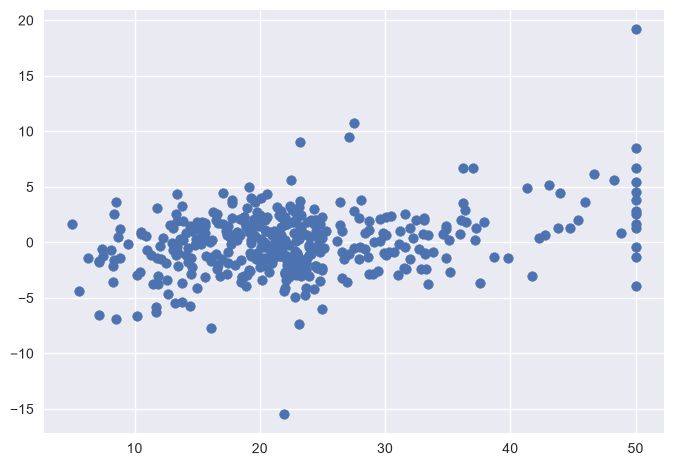

In [23]:
from sklearn.preprocessing import PolynomialFeatures
#transformaciones a las features. Hiperparametro: el grado. SOLO A LAS X, NO A LAS Y!!!!!!!!
poly_x = PolynomialFeatures(degree=2)
X_train_poly = poly_x.fit_transform(X_train)
X_test_poly = poly_x.transform(X_test)

# Regresión lineal sobre las features polinómicas
pol_reg = LinearRegression()
pol_reg.fit(X_train_poly, y_train)
plt.scatter(y_train, y_train - pol_reg.predict(X_train_poly));

In [24]:
print(f"RMSE_train_poly: {root_mean_squared_error(y_train, pol_reg.predict(X_train_poly))}")

y_poly_predict = pol_reg.predict(X_test_poly)
error_test = root_mean_squared_error(y_test, y_poly_predict)
print(f"RMSE_test_poly: {error_test}")

RMSE_train_poly: 2.8767489771803216
RMSE_test_poly: 3.9020509881418612


Mejora al aumentar el grado del polinomio a 2, y ahora regularizar a ver si mejora con un alpha optimo:

In [37]:
#-------------------------REGULARIZACIÓN LASSO----------------------
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

def evalua(modelo, X_train, y_train, X_test, y_test):
    modelo.fit(X_train_poly, y_train)
    print("Train MSE poly regularizado:", round(root_mean_squared_error(y_train, modelo.predict(X_train_poly)), 3))
    print("Test MSE poly regularizado:", round(root_mean_squared_error(y_test, modelo.predict(X_test_poly)), 3))
    return modelo

# Se instancia en el parametro de evalua y se ajusta dentro de la funcion evalua
lasso = evalua(Ridge(alpha=0.004), X_train_poly, y_train, X_test_poly, y_test)

print("Coeficientes a cero:", (lasso.coef_ == 0).sum(), "de", len(lasso.coef_))

Train MSE poly regularizado: 2.725
Test MSE poly regularizado: 3.627
Coeficientes a cero: 1 de 78


Mejora con regularización ridge y un alpha minimo posible